# Phishing Website Detection

A machine learning project in Python.
The goal is to classify a website as **phishing** or **legitimate** from 30 features that were already extracted from each site (URL length, whether it uses an IP address, SSL state, domain age, and so on).

**Dataset:** UCI *Phishing Websites* dataset (Mohammad, Thabtah and McCluskey), 11,055 websites, licensed CC BY 4.0.
In the `Result` column, `-1` means phishing and `1` means legitimate.

**Models:** K-Nearest Neighbors, Logistic Regression, and Random Forest, each tuned with 5-fold cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arff

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load and look at the data

In [2]:
import os

DATA_PATH = "data/Training Dataset.arff"
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError("Download Training Dataset.arff from https://archive.ics.uci.edu/dataset/327/phishing+websites and put it in the data folder.")

with open(DATA_PATH) as f:
    raw = arff.load(f)

df = pd.DataFrame(raw["data"], columns=[a[0] for a in raw["attributes"]]).astype(int)

print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print()
print(df["Result"].map({-1: "phishing", 1: "legitimate"}).value_counts())
df.head()

Shape: (11055, 31)
Missing values: 0

Result
legitimate    6157
phishing      4898
Name: count, dtype: int64


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


### Duplicate rows

The features only take the values -1, 0 and 1, so many different websites end up with exactly the same row.
If identical rows land in both the training set and the test set, the model is partly tested on data it has already seen, and the scores look better than they really are.
Let me check how big the problem is.

In [3]:
n_dup = int(df.duplicated().sum())
print(f"Duplicate rows: {n_dup} of {len(df)} ({n_dup / len(df):.0%})")
print(f"Rows left after removing duplicates: {len(df) - n_dup}")

df_unique = df.drop_duplicates().reset_index(drop=True)
print()
print(df_unique["Result"].map({-1: "phishing", 1: "legitimate"}).value_counts())

Duplicate rows: 5206 of 11055 (47%)
Rows left after removing duplicates: 5849

Result
phishing      3019
legitimate    2830
Name: count, dtype: int64


## 2. Setup for the experiments

* The target is changed so that **1 = phishing** and 0 = legitimate. This way recall and precision are measured for the class that matters in security work.
* The data is split **before** any scaling, and the split is stratified so both sets keep the same class balance.
* Scaling is done inside a scikit-learn `Pipeline`, so the scaler only learns from training data.
* Each model is tuned with `GridSearchCV` (5-fold stratified cross-validation, scoring on F1).

In [4]:
def make_xy(data):
    X = data.drop(columns=["Result"])
    y = (data["Result"] == -1).astype(int)   # 1 = phishing, 0 = legitimate
    return X, y

def model_grids():
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    knn = Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier())])
    logreg = Pipeline([("scale", StandardScaler()),
                       ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
    forest = Pipeline([("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
    return {
        "KNN": GridSearchCV(knn, {"clf__n_neighbors": [3, 5, 7, 9, 15],
                                  "clf__weights": ["uniform", "distance"]},
                            scoring="f1", cv=cv, n_jobs=-1),
        "Logistic Regression": GridSearchCV(logreg, {"clf__C": [0.01, 0.1, 1, 10]},
                                            scoring="f1", cv=cv, n_jobs=-1),
        "Random Forest": GridSearchCV(forest, {"clf__n_estimators": [100, 300],
                                               "clf__max_depth": [None, 10, 20],
                                               "clf__min_samples_leaf": [1, 2, 4]},
                                      scoring="f1", cv=cv, n_jobs=-1),
    }

def run_experiment(data):
    X, y = make_xy(data)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
    fitted, rows = {}, []
    for name, search in model_grids().items():
        search.fit(X_train, y_train)
        pred = search.predict(X_test)
        proba = search.predict_proba(X_test)[:, 1]
        fitted[name] = (search, pred, proba)
        rows.append({"Model": name,
                     "CV F1": search.best_score_,
                     "Accuracy": accuracy_score(y_test, pred),
                     "Precision": precision_score(y_test, pred),
                     "Recall": recall_score(y_test, pred),
                     "F1": f1_score(y_test, pred),
                     "ROC-AUC": roc_auc_score(y_test, proba)})
    return fitted, pd.DataFrame(rows).set_index("Model"), X_train, X_test, y_train, y_test

## 3. Experiment A: all 11,055 rows (duplicates kept)

This is the setup most tutorials use. I include it only to show how much the duplicates inflate the scores.

In [5]:
fit_a, res_a, *_ = run_experiment(df)
res_a.round(4)

,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
KNN,0.9495,0.9697,0.9800,0.9510,0.9653,0.9937
Logistic Regression,0.9180,0.9281,0.9344,0.9010,0.9174,0.9785
Random Forest,0.9661,0.9769,0.9834,0.9643,0.9737,0.9975


## 4. Experiment B: duplicates removed (main result)

The duplicates are dropped before the split, so no identical row can appear in both training and test data.
These are the numbers I trust.

In [6]:
fit_b, res_b, X_train, X_test, y_train, y_test = run_experiment(df_unique)
print(f"Train: {X_train.shape[0]} rows, Test: {X_test.shape[0]} rows")
res_b.round(4)

Train: 4679 rows, Test: 1170 rows


,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
KNN,0.9173,0.9214,0.9169,0.9321,0.9245,0.9754
Logistic Regression,0.9232,0.9171,0.9261,0.9123,0.9191,0.9772
Random Forest,0.9493,0.9393,0.9587,0.9222,0.9401,0.9875


In [7]:
for name, (search, _, _) in fit_b.items():
    print(f"{name}: best parameters = {search.best_params_}")

res_b.round(4).to_csv("results/model_comparison.csv")

KNN: best parameters = {'clf__n_neighbors': 15, 'clf__weights': 'uniform'}
Logistic Regression: best parameters = {'clf__C': 0.1}
Random Forest: best parameters = {'clf__max_depth': 20, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300}


## 5. Results

### Model comparison

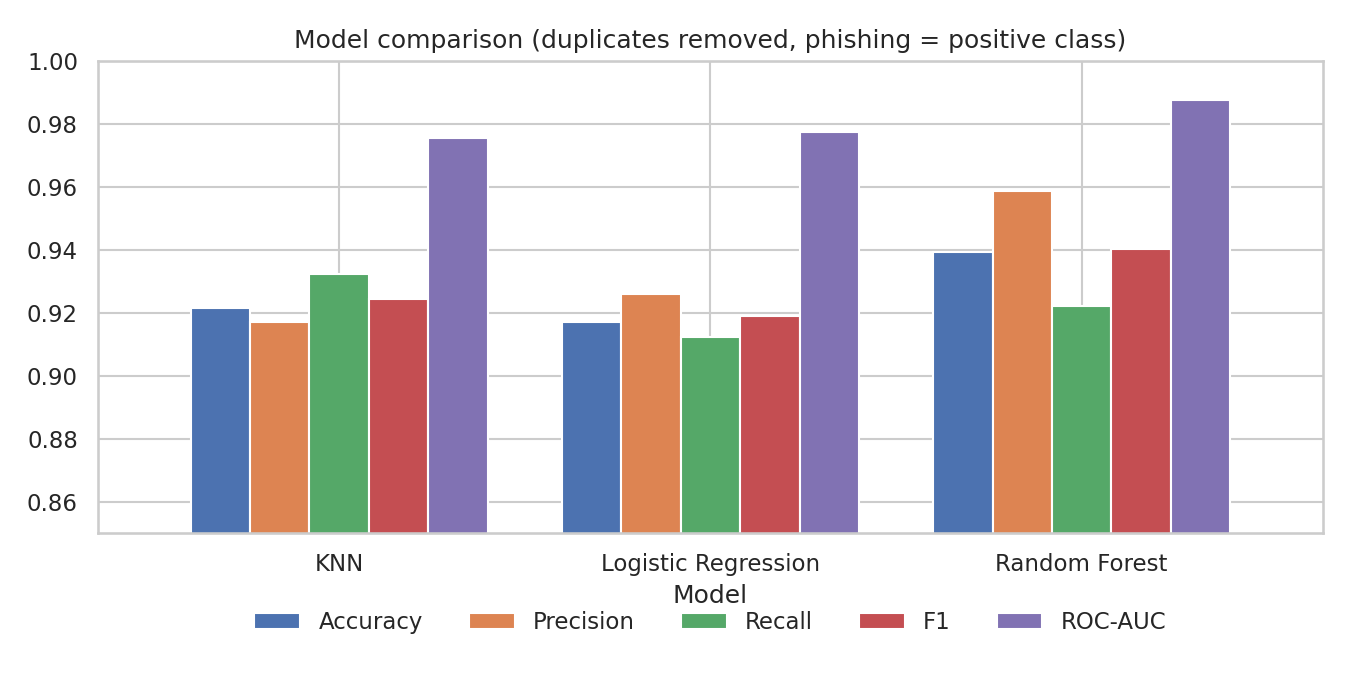

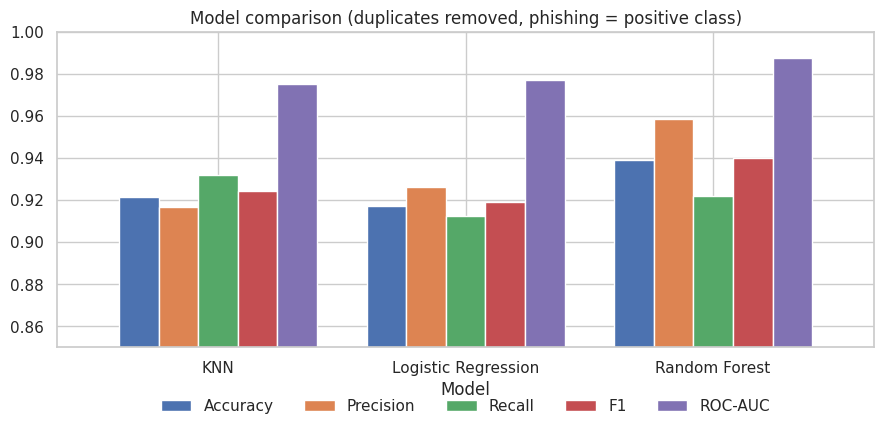

In [8]:
ax = res_b[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(9, 4.5), rot=0, width=0.8)
ax.set_ylim(0.85, 1.0)
ax.set_title("Model comparison (duplicates removed, phishing = positive class)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=False)
plt.tight_layout()
plt.savefig("figures/model_comparison.png", dpi=150)
plt.show()

### Confusion matrix of the best model

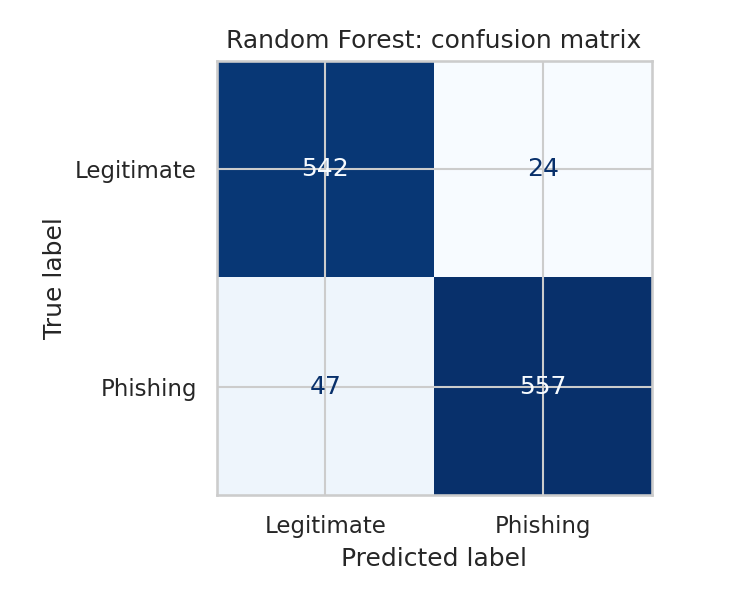

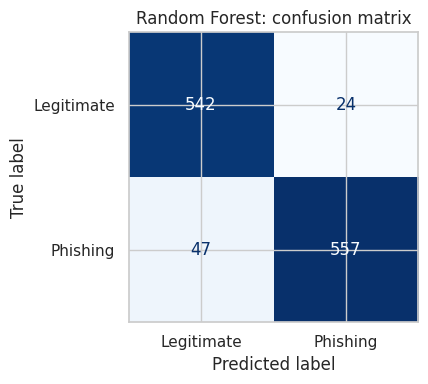

Phishing sites caught: 557
Phishing sites missed (false negatives): 47
Legitimate sites wrongly flagged (false positives): 24
Legitimate sites correctly passed: 542


In [9]:
best_name = res_b["F1"].idxmax()
_, best_pred, best_proba = fit_b[best_name]

cm = confusion_matrix(y_test, best_pred)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Phishing"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{best_name}: confusion matrix")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Phishing sites caught: {tp}")
print(f"Phishing sites missed (false negatives): {fn}")
print(f"Legitimate sites wrongly flagged (false positives): {fp}")
print(f"Legitimate sites correctly passed: {tn}")

### ROC curves

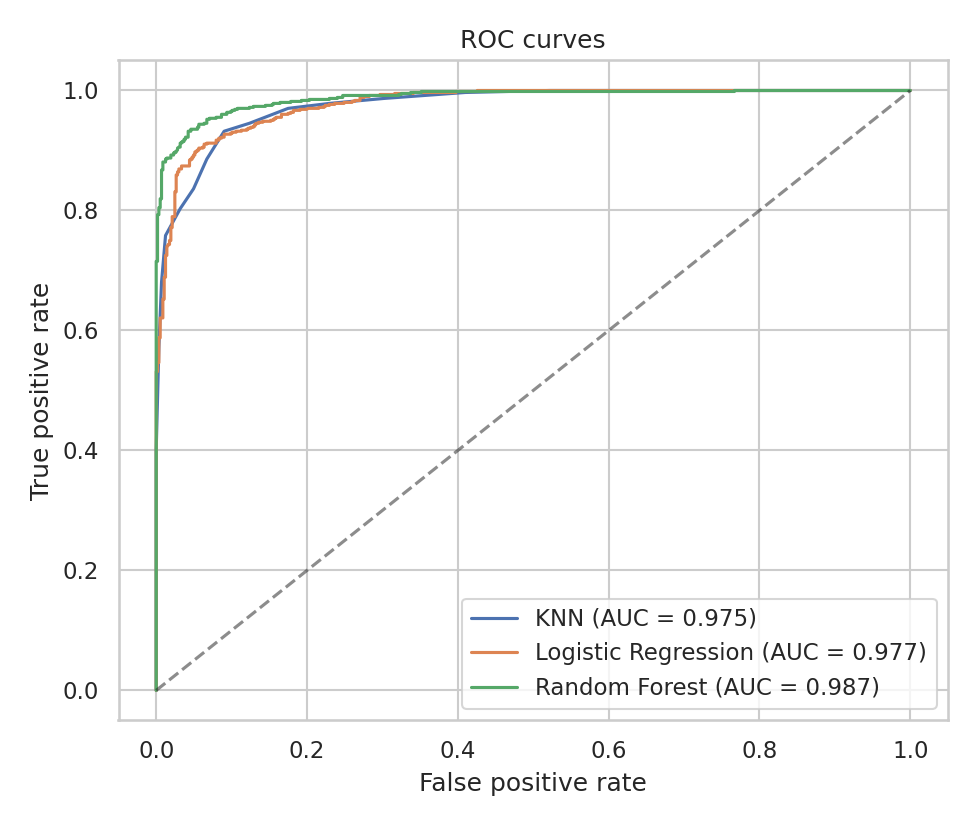

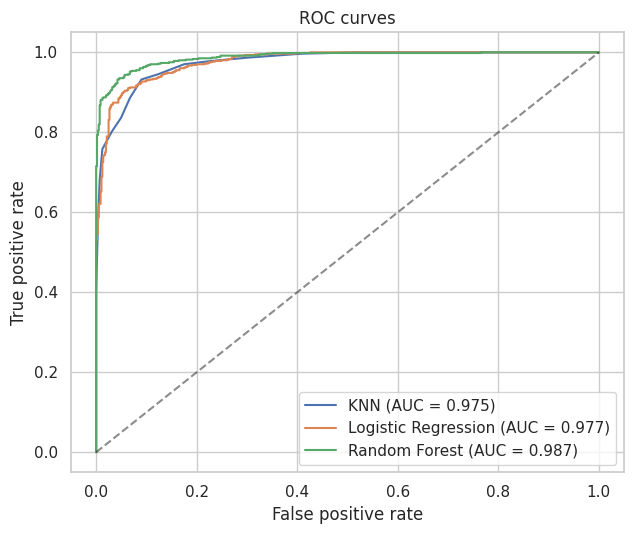

In [10]:
plt.figure(figsize=(6.5, 5.5))
for name, (_, _, proba) in fit_b.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/roc_curves.png", dpi=150)
plt.show()

### Which features matter most?

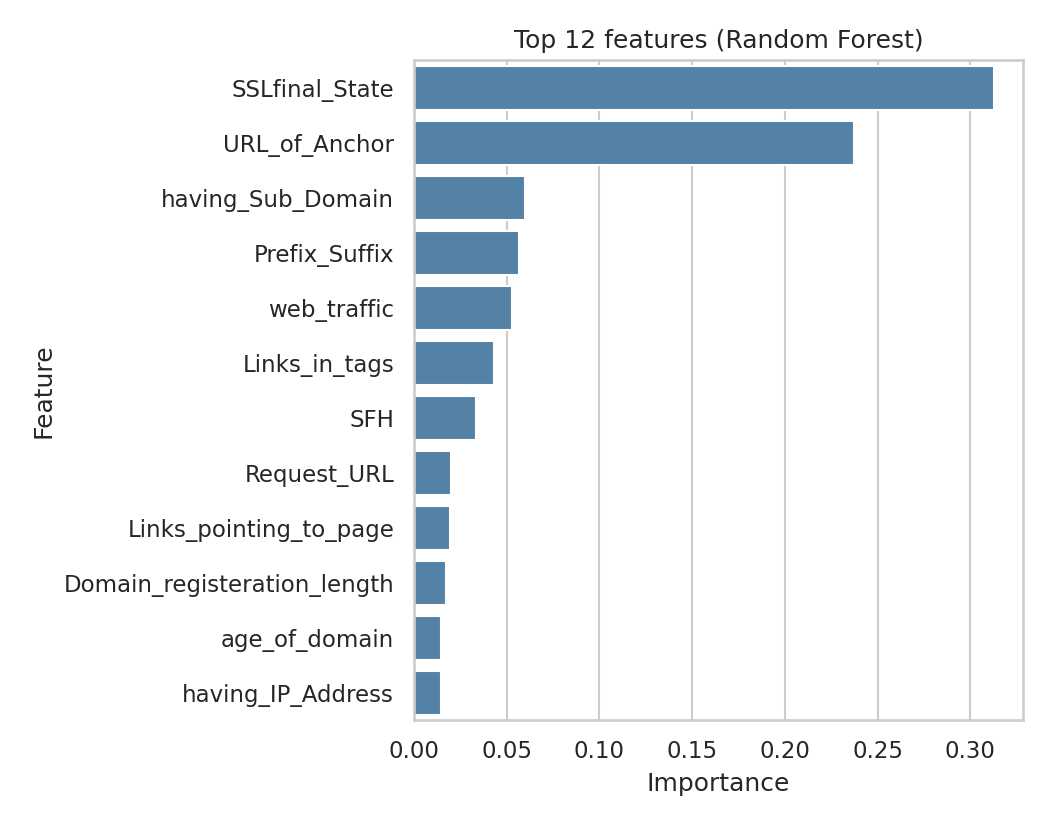

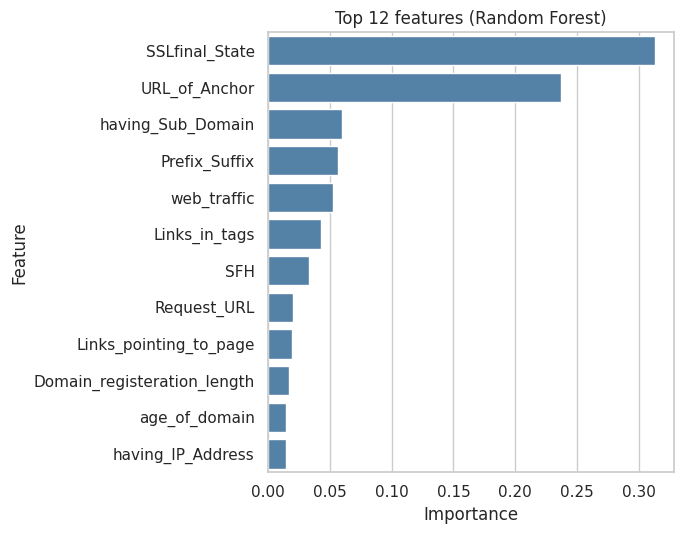

SSLfinal_State                 0.313
URL_of_Anchor                  0.237
having_Sub_Domain              0.060
Prefix_Suffix                  0.056
web_traffic                    0.053
Links_in_tags                  0.043
SFH                            0.033
Request_URL                    0.020
Links_pointing_to_page         0.020
Domain_registeration_length    0.017
age_of_domain                  0.015
having_IP_Address              0.014
dtype: float64

In [11]:
forest = fit_b["Random Forest"][0].best_estimator_.named_steps["clf"]
importance = pd.Series(forest.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(7, 5.5))
sns.barplot(x=importance.head(12).values, y=importance.head(12).index, color="steelblue")
plt.title("Top 12 features (Random Forest)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=150)
plt.show()

importance.head(12).round(3)

### Effect of the duplicates

In [12]:
compare = pd.DataFrame({
    "Accuracy (duplicates kept)": res_a["Accuracy"],
    "Accuracy (duplicates removed)": res_b["Accuracy"],
    "Recall (duplicates kept)": res_a["Recall"],
    "Recall (duplicates removed)": res_b["Recall"],
})
compare.round(4)

,Accuracy (duplicates kept),Accuracy (duplicates removed),Recall (duplicates kept),Recall (duplicates removed)
Model,,,,
KNN,0.9697,0.9214,0.9510,0.9321
Logistic Regression,0.9281,0.9171,0.9010,0.9123
Random Forest,0.9769,0.9393,0.9643,0.9222


## 6. Conclusions

* **Best model:** Random Forest. With duplicates removed it reached **93.9% accuracy, 95.9% precision, 92.2% recall for phishing and an ROC-AUC of 0.987** on a test set of 1,170 websites. It caught 557 of the 604 phishing sites in the test set and wrongly flagged 24 of the 566 legitimate ones.
* **Duplicates matter a lot.** 47% of the rows (5,206 of 11,055) are exact duplicates. Keeping them raised the Random Forest accuracy from 93.9% to 97.7%, because identical rows end up in both the training and the test set. My first version of this project (no tuning, no duplicate removal, scaling done before the split) reported 97% for Random Forest and 94% for KNN. The honest figure is about 94%.
* **Most important features:** `SSLfinal_State` (31%) and `URL_of_Anchor` (24%) together carry more than half of the Random Forest importance, so how a site handles HTTPS and where its links point are the strongest signals in this dataset.
* **Recall is the number to watch.** In security work a missed phishing site is worse than a false alarm. At 92% recall about 1 in 13 phishing sites is missed. A next step would be to lower the decision threshold to trade some precision for recall. I did not do that here.
* **Limitations:** the dataset contains pre-computed features and no URLs, so the models cannot classify a new URL by themselves. The data is also old, and the results come from a single train/test split, so they should not be read as performance on phishing sites today.